# Module 11: Classifying Cells from Gene Expression (scRNA-seq B-cell classifier)

This notebook has two parts:

* **Part A – Scanpy Basics tutorial** (preprocessing, clustering and cell-type annotation of two 10x PBMC samples).
* **Part B – Module 11 assignment**: Cells 1–6 train logistic regression, random forest and RBF SVM classifiers to predict **B Cells** vs other annotated cells, followed by the exit questions (Cell 7).

Run every cell top to bottom (Runtime → Run all). Cell 4 can take several minutes.

# Part A — Scanpy Basics tutorial

## Setup

In [ ]:
!pip install -q "scanpy[leiden]" pooch

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [ ]:
import anndata as ad
import pooch
import scanpy as sc

sc.settings.set_figure_params(dpi=50, facecolor="white")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/tmp/ipykernel_446/733553852.py:5: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor="white")


In [ ]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [ ]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/tmp/ipykernel_446/3491096135.py:13: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label="sample")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'
    layers: None (.X)

## Quality control

In [ ]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

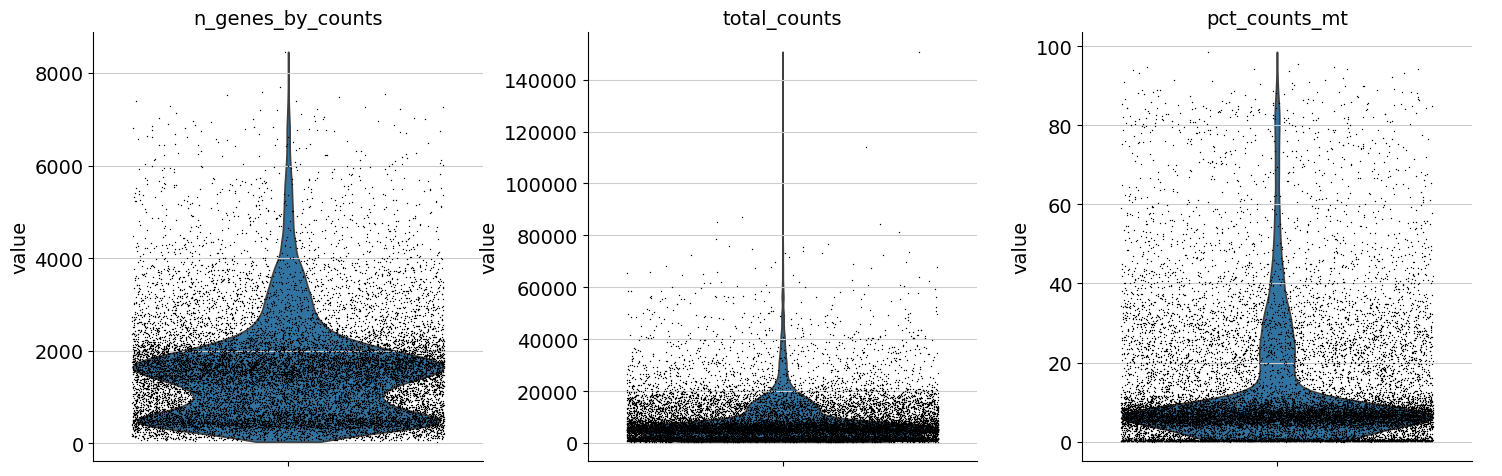

In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

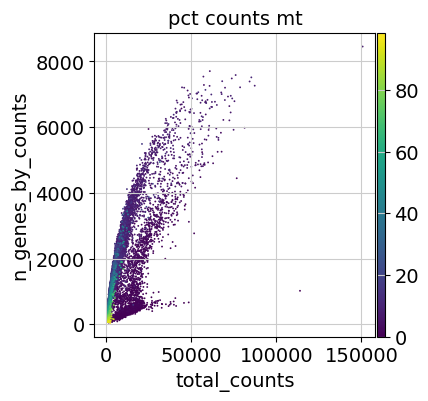

In [ ]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

## Doublet detection

In [ ]:
sc.pp.scrublet(adata, batch_key="sample")

## Normalization

In [ ]:
# Saving count data (Module 11 Cell 2 uses this layer)
adata.layers["counts"] = adata.X.copy()

# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

## Feature selection

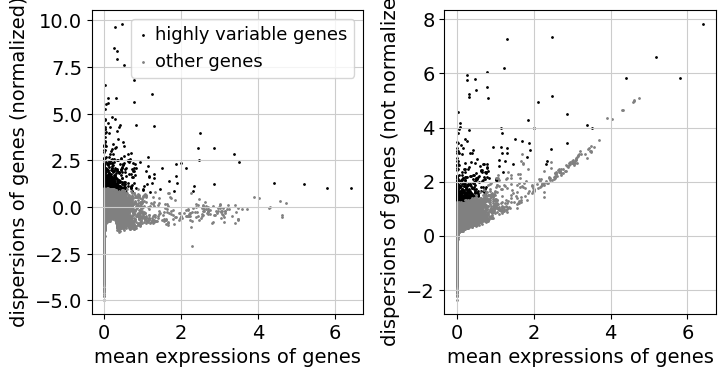

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata)

## Dimensionality reduction

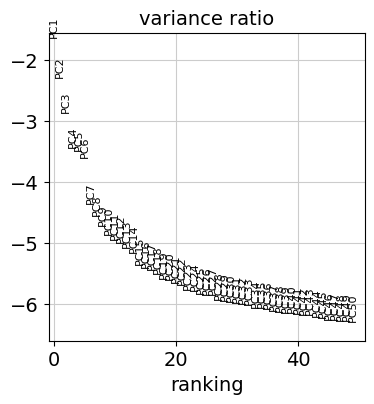

In [ ]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

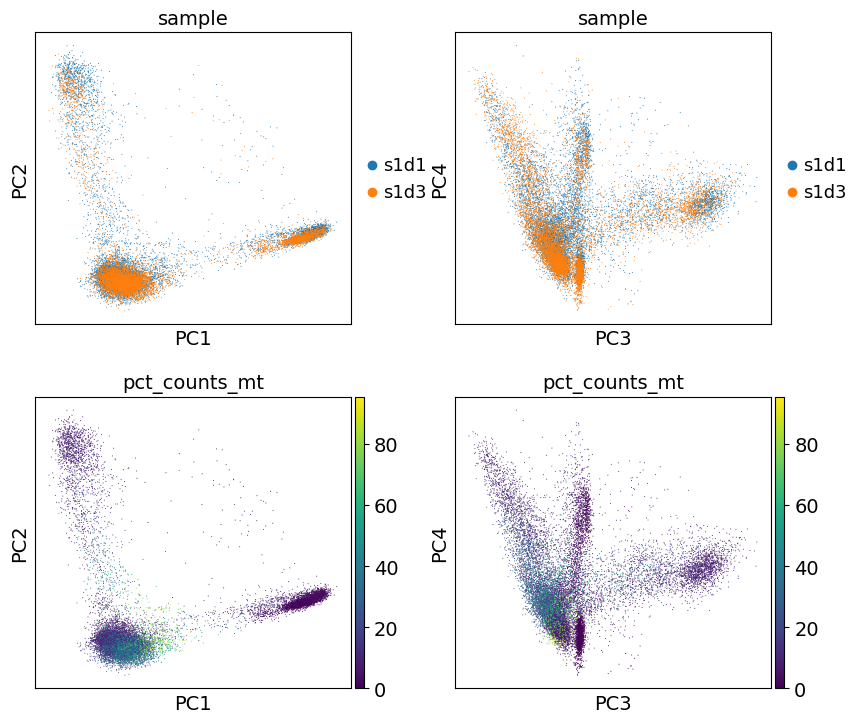

In [ ]:
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

## Nearest neighbor graph construction and visualization

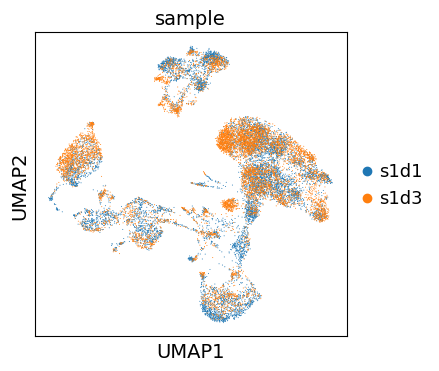

In [ ]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(adata, color="sample", size=2)

## Clustering

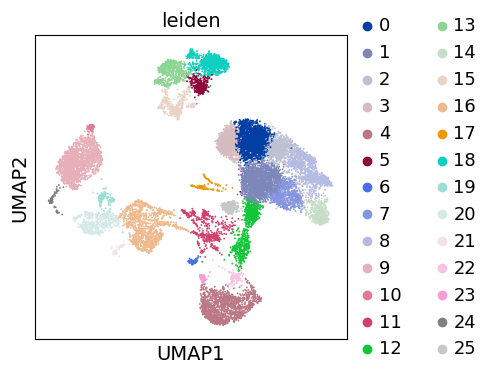

In [ ]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)
sc.pl.umap(adata, color=["leiden"])

## Re-assess quality control and cell filtering

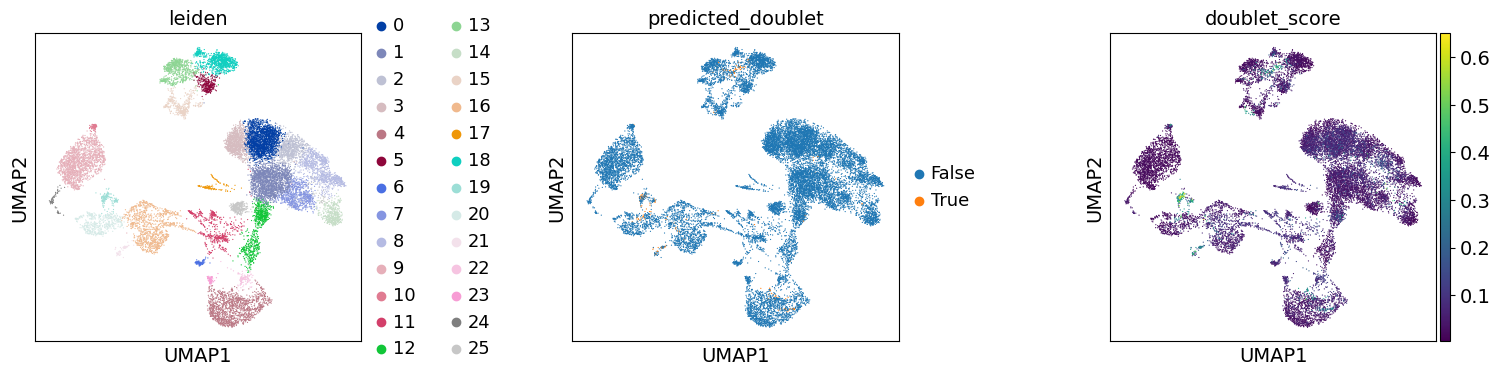

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

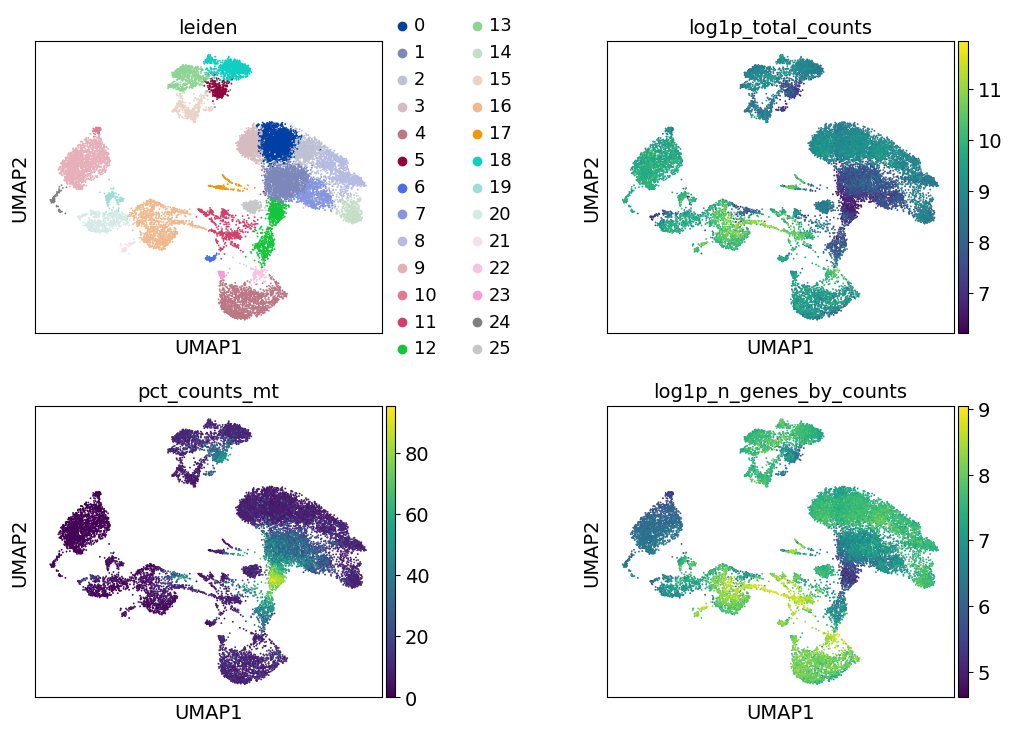

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

## Manual cell-type annotation

In [ ]:
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(
        adata, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

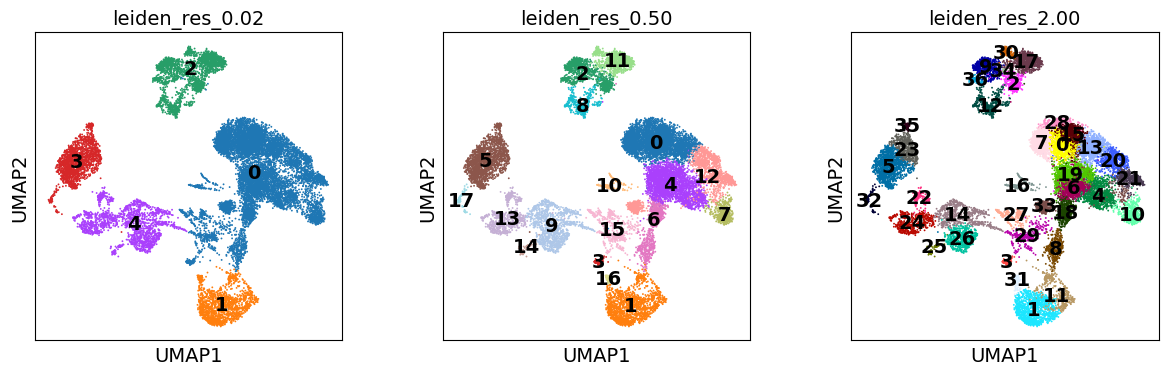

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

### Marker gene set

In [ ]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNGR1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHM should be negative
    "B cells": [
        "MS4A1", "ITGB1", "COL4A4", "PRDM1", "IRF4",
        "PAX5", "BCL11A", "BLK", "IGHD", "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

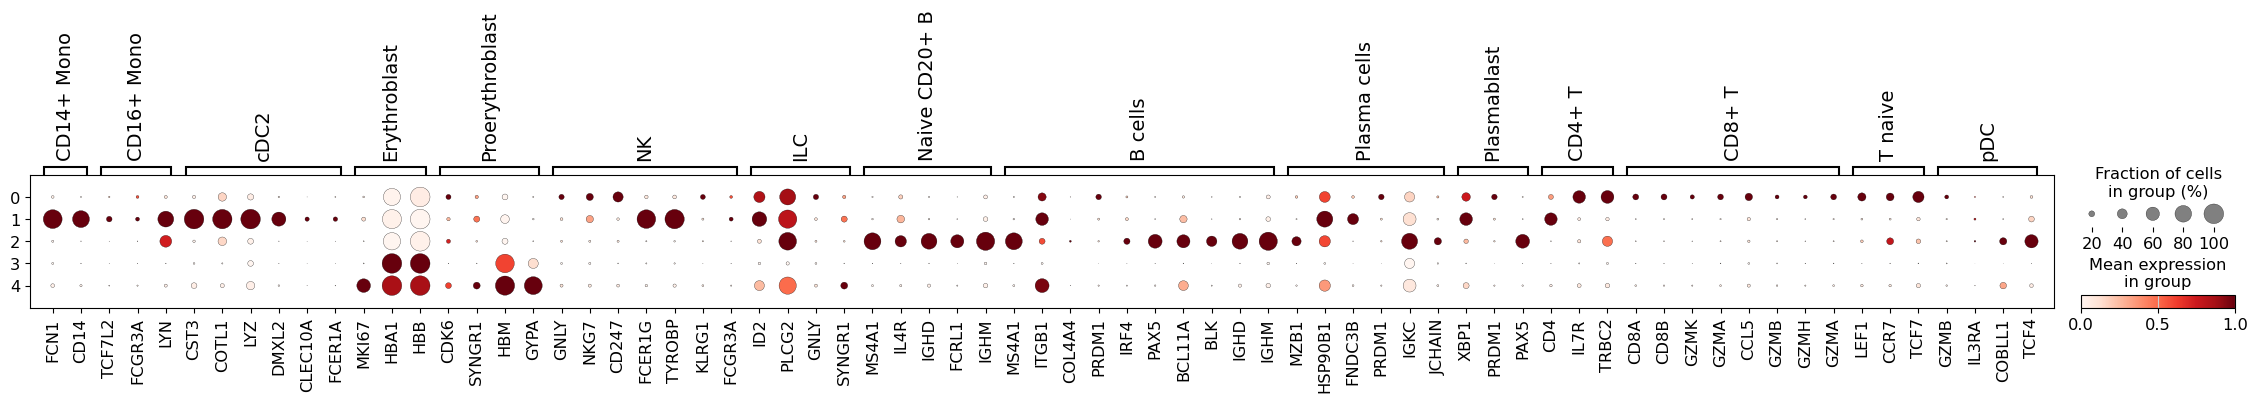

In [ ]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")

Map the coarse clusters to level-1 cell types using the dot plot above. In this run `leiden_res_0.02` produced **five** clusters (0–4):
* **0** – T/NK markers (IL7R, TRBC2, LEF1, CCR7, CD247) → Lymphocytes
* **1** – FCN1, CD14, LYZ, CST3 → Monocytes
* **2** – MS4A1, PAX5, BLK, IGHD, IGHM, FCRL1 → **B Cells**
* **3** – HBA1, HBB, HBM → Erythroid
* **4** – MKI67, HBA1, HBB, HBM, GYPA → Erythroid (erythroid progenitors)

The tutorial's default mapping (`"3": "B Cells"`) does not match this run, so it is corrected below.

cell_type_lvl1
Lymphocytes    9763
Erythroid      3502
B Cells        2269
Monocytes      1507
Name: count, dtype: int64


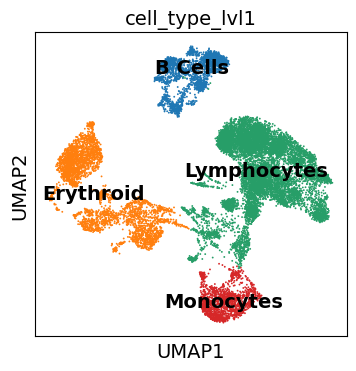

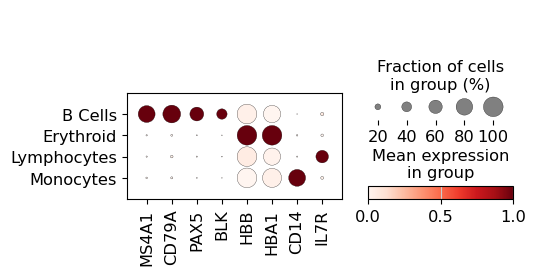

In [ ]:
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "B Cells",
        "3": "Erythroid",
        "4": "Erythroid",
    }
)
print(adata.obs["cell_type_lvl1"].value_counts(dropna=False))
sc.pl.umap(adata, color="cell_type_lvl1", legend_loc="on data")

# Sanity check: the cells labelled "B Cells" must express the B-cell markers.
sc.pl.dotplot(
    adata,
    ["MS4A1", "CD79A", "PAX5", "BLK", "HBB", "HBA1", "CD14", "IL7R"],
    groupby="cell_type_lvl1",
    standard_scale="var",
)

### Differentially expressed genes as markers

In [ ]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")

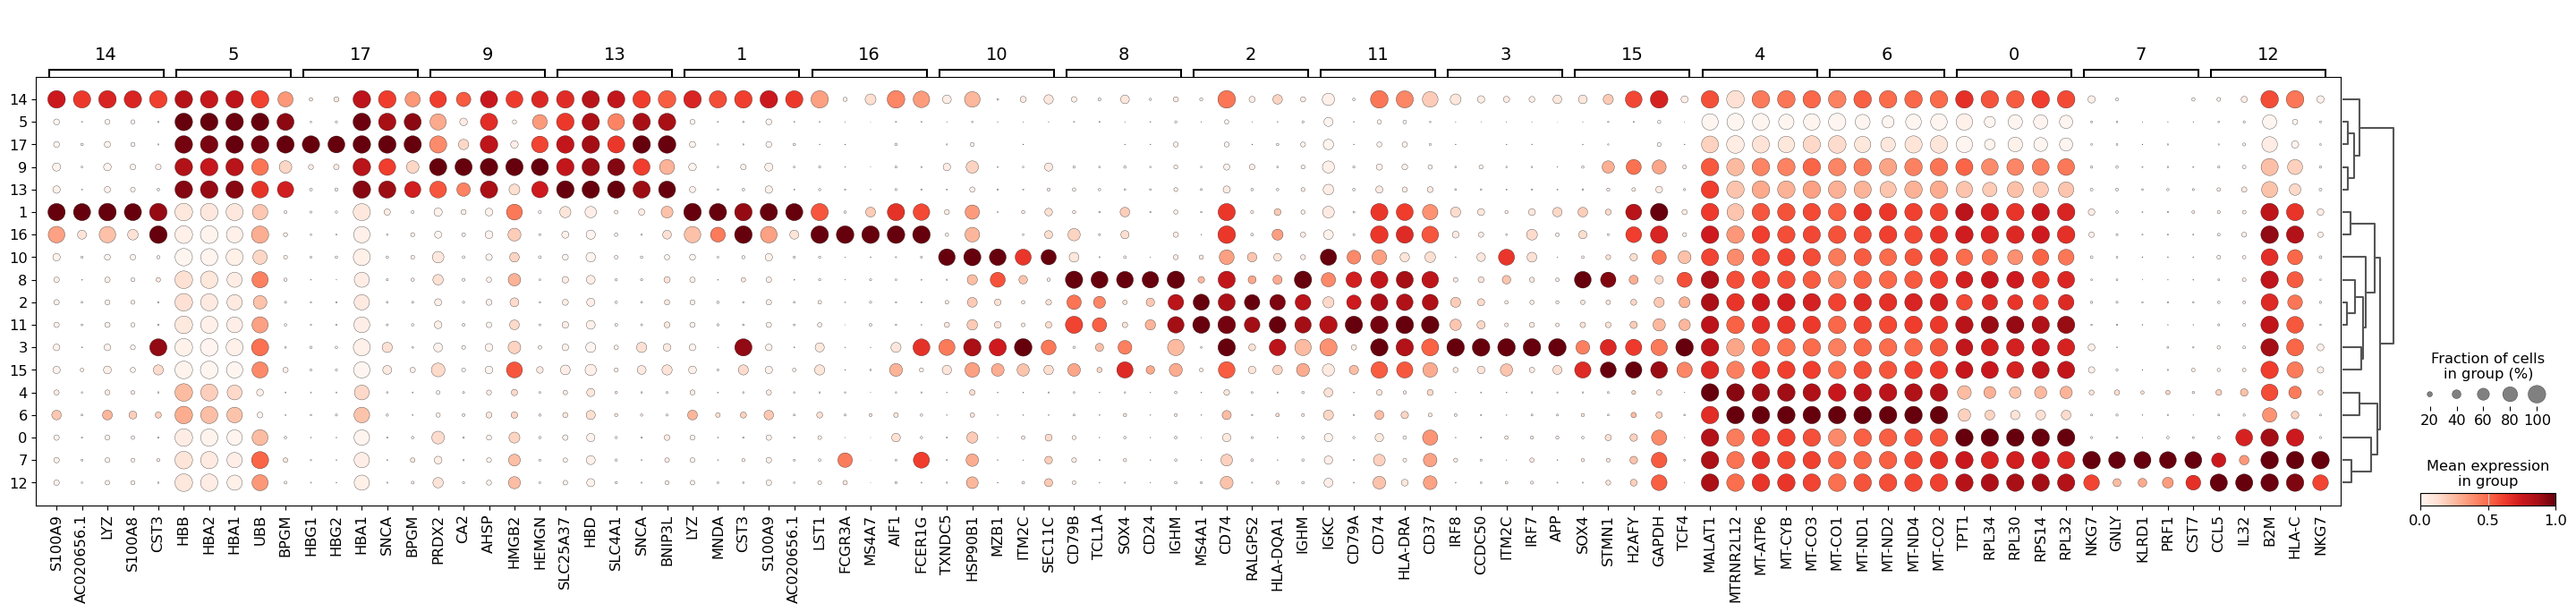

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5
)

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.537918,6.548978,1.277051e-276,2.991748e-272
1,GNLY,33.851448,7.374753,3.455431e-251,4.047519e-247
2,KLRD1,33.814442,5.832656,1.209767e-250,9.447073e-247
3,PRF1,33.023769,5.431675,3.703158e-239,2.168847e-235
4,CST7,33.007786,5.233107,6.280117e-239,2.942486e-235


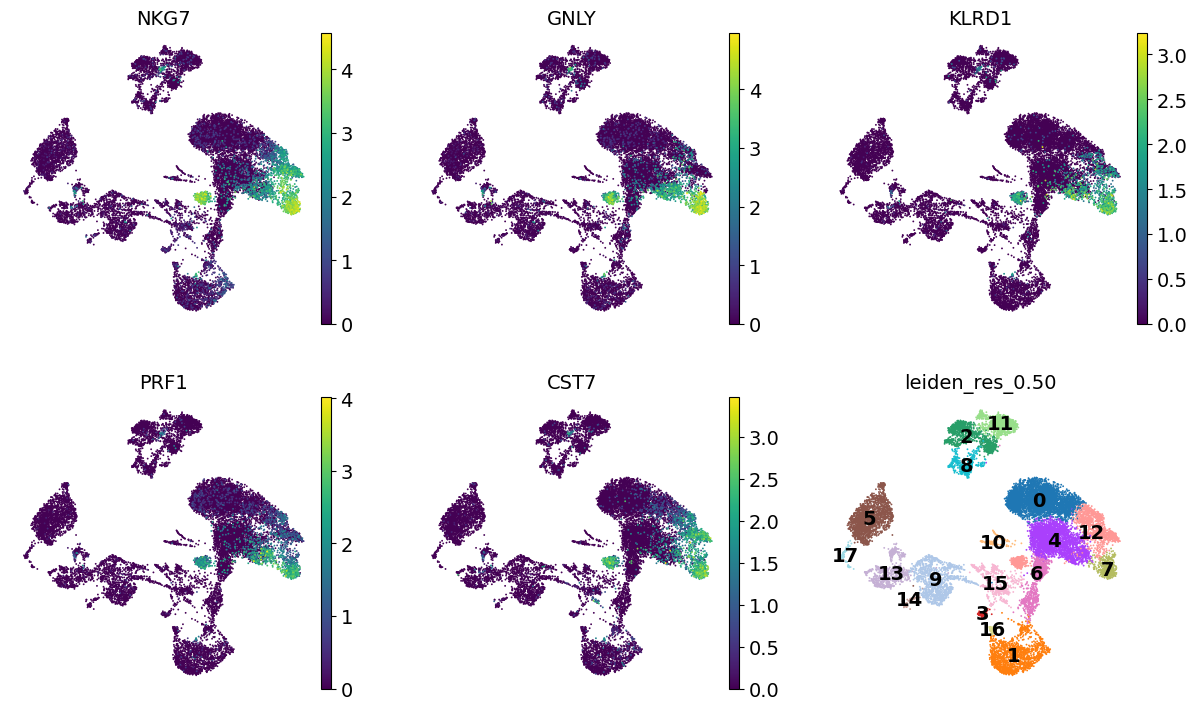

In [ ]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

# Part B — Module 11: B-cell classifier

**Workflow**
* Split cells into 60% training, 20% validation and 20% test.
* Use five-fold cross-validation and grid search within training to choose hyperparameters for each classifier family.
* Choose the winning classifier using validation average precision.
* Evaluate that classifier on the test set without further tuning.

## Cell 1: Import tools and define settings
Imports the classifiers and evaluation tools. 500 predictor genes are selected inside each training fold to keep computation manageable.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

## Cell 2: Prepare expression data and split the cells
Assigns B Cells the label 1 and other annotated cells the label 0. Normalizes each cell to a fixed total and log-transforms its expression. Creates stratified training, validation and test partitions. This creates a separate matrix and leaves `adata` unchanged.

In [ ]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1361,8863,0.133
1,Validation,3408,454,2954,0.133
2,Test,3409,454,2955,0.133


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


## Cell 3: Define pipelines and search grids
Each pipeline removes constant genes and selects genes associated with the training labels. Logistic regression and SVM also scale those features. Placing feature selection and scaling inside the pipeline ensures each cross-validation fold fits these steps using only its training cells. The tutorial's all-cell PCA and selected genes are not reused.

In [ ]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

## Cell 4: Run five-fold grid search and choose the classifier
Grid search selects the hyperparameters with the highest mean cross-validation average precision for each classifier family and refits that configuration on the full training partition. The three models are compared on validation average precision and the winner is selected. SVM supplies continuous decision scores instead of probabilities; both average precision and ROC-AUC can use these scores. **This cell may take several minutes.**

In [ ]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9988,0.0008,0.9986,0.9998,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9985,0.0008,0.9977,0.9997,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9981,0.0013,0.9972,0.9996,{'classifier__C': 0.1}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.


If validation average precision is exactly tied, this code retains the original model order: logistic regression, random forest, then SVM. A displayed tie after rounding does not necessarily mean the underlying values are identical.

## Cell 5: Compare validation ROC curves
Plots the best model from each classifier family on the validation set. The x-axis is the false positive rate and the y-axis is B-cell recall. The legend reports ROC-AUC. These plots describe performance; the selection criterion remains validation average precision.

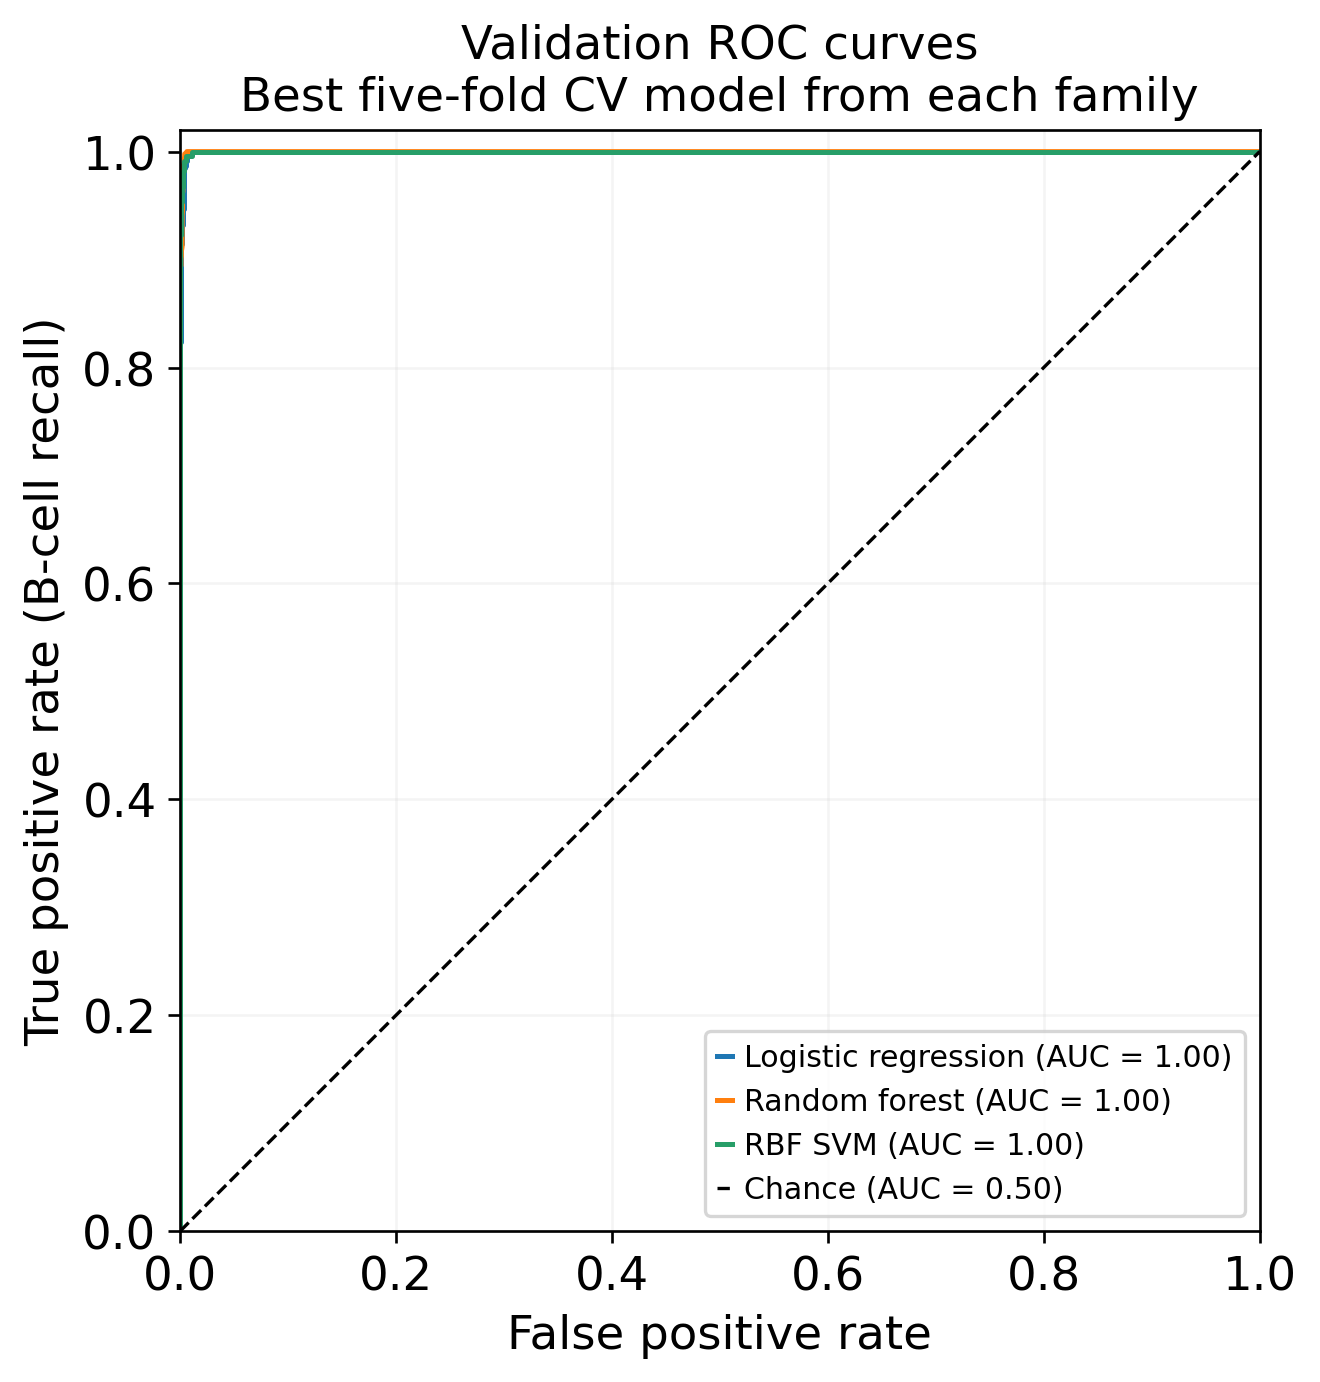

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

## Cell 6: Evaluate the winner on the test set
Evaluates the selected model without further tuning or refitting. Reports test average precision, ROC-AUC and classification metrics, then displays its ROC curve and confusion matrix. The confusion matrix uses the model's default classification threshold.

Final test evaluation: RBF SVM
Test average precision: 0.9978
Test ROC-AUC:           0.9997
Test B-cell prevalence: 0.1332

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.997     0.995     0.996      2955
              B Cells      0.967     0.982     0.975       454

             accuracy                          0.993      3409
            macro avg      0.982     0.989     0.985      3409
         weighted avg      0.993     0.993     0.993      3409



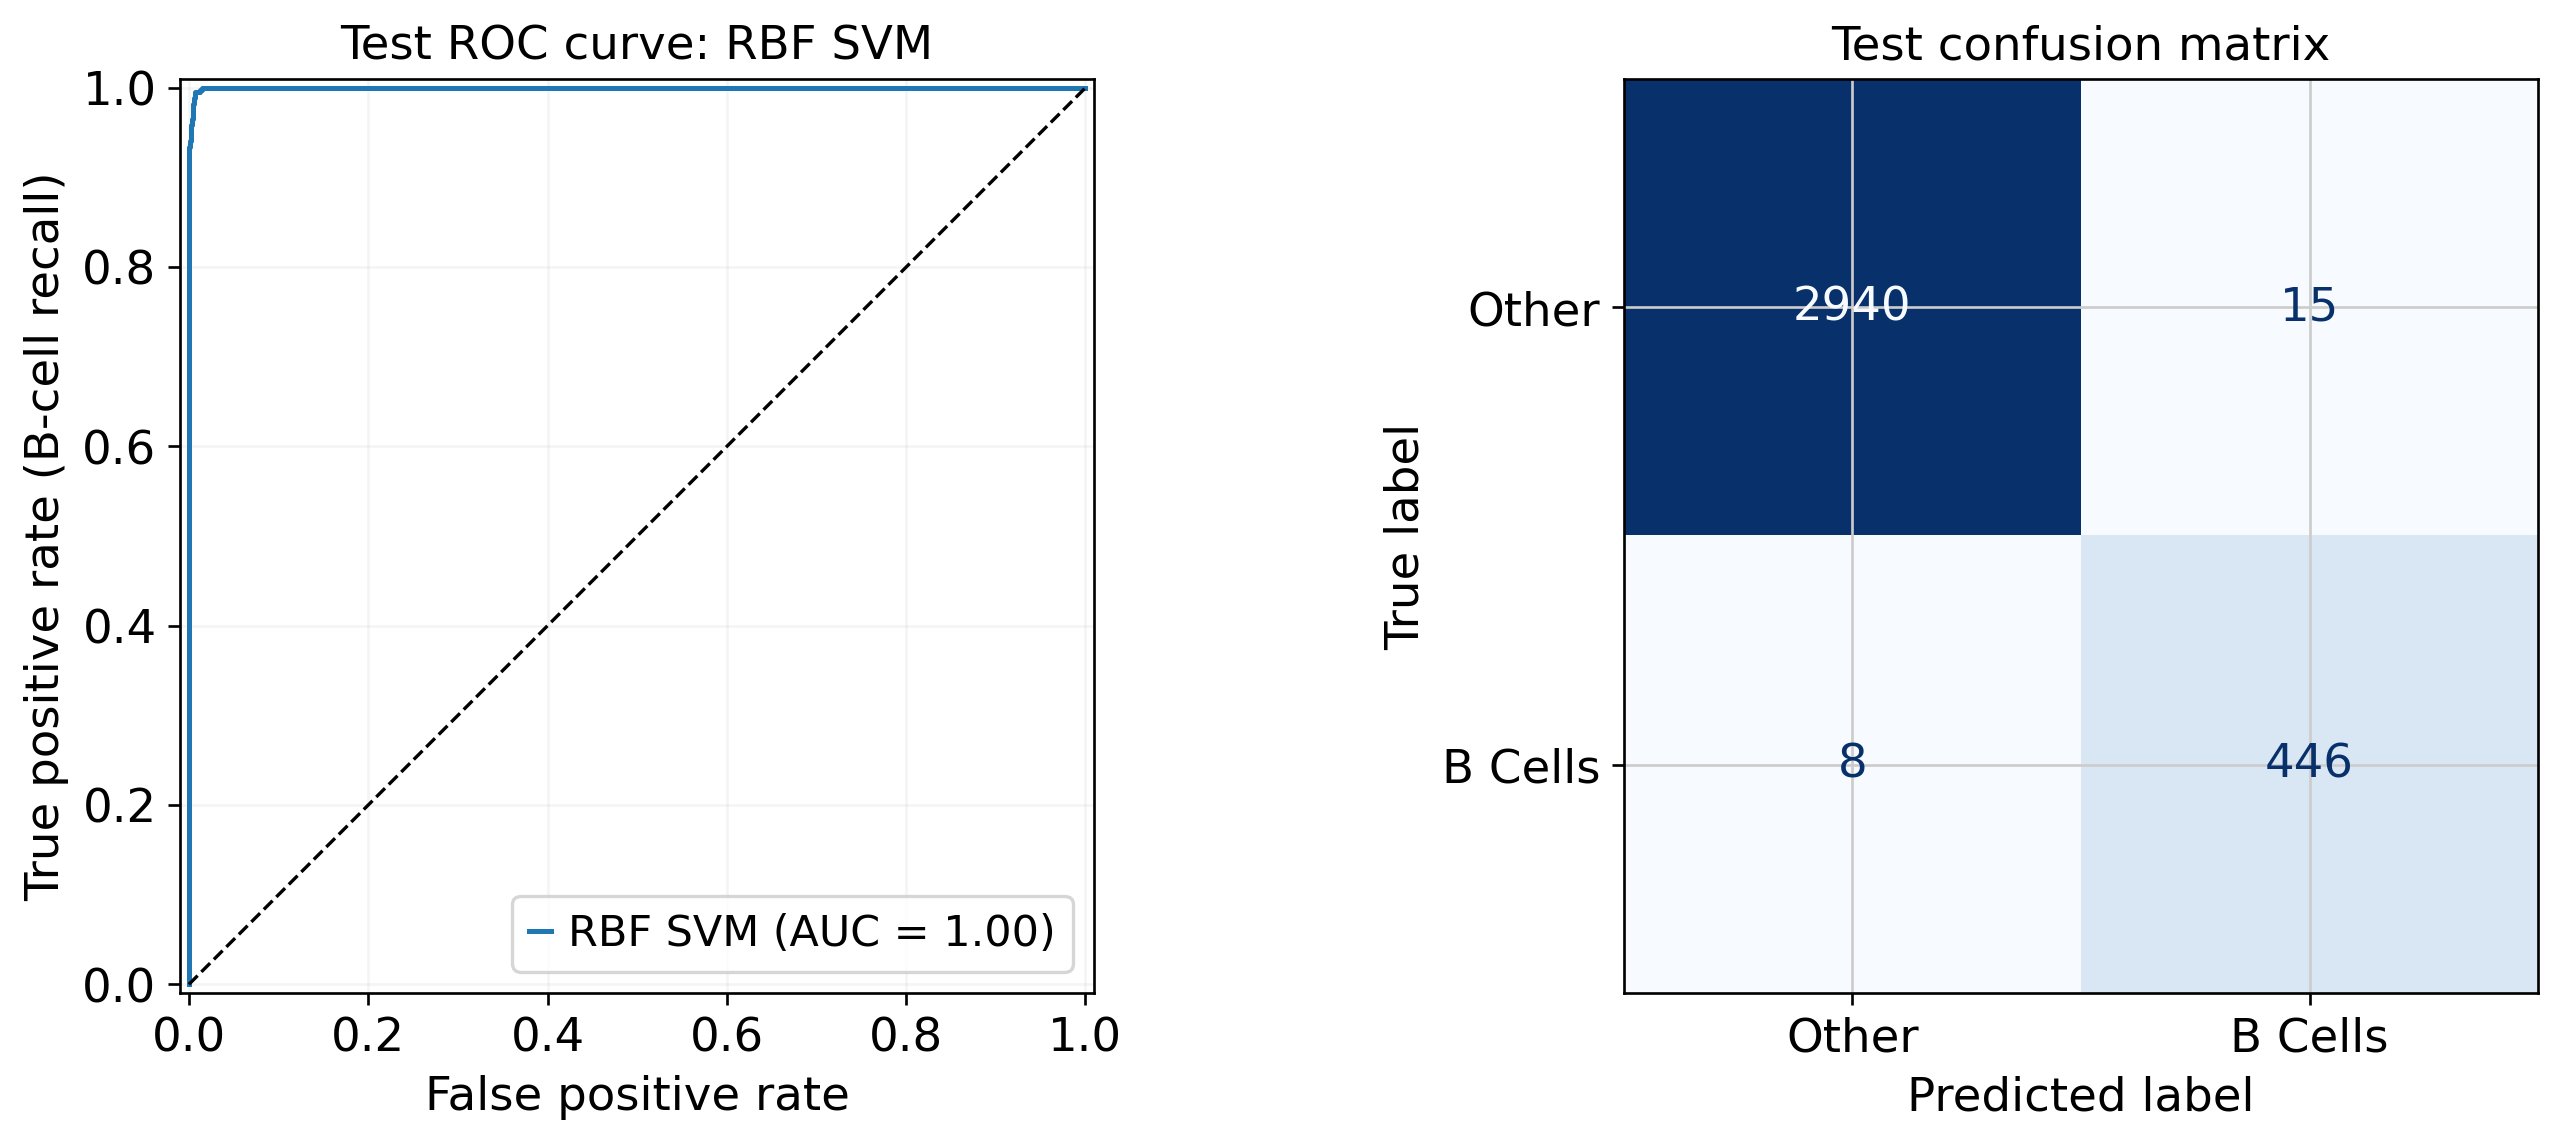

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,ATTCCTAAGTCTGGTT-1,0,0,-3.123282,True
1,CCCGGAAGTCGAAACG-1,0,0,-1.761799,True
2,GTCCTCAGTGCAGGAT-1,0,0,-1.489165,True
3,GCTGAATGTCTTTCTA-1,0,0,-3.174368,True
4,GGGTCACTCGCATAGT-1,0,0,-1.702041,True


In [ ]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

## Helper: numbers for the exit questions (optional)
Prints every number needed for Questions 2, 3 and 6 so the answers below can be filled in exactly from your own run. It only reads results already computed; it does not retrain or retune anything.

In [ ]:
from sklearn.metrics import confusion_matrix

# Q2 baseline: predict "Other" for every training cell
baseline_acc = (y_train == 0).mean()
print("Q2 - Training cells:", len(y_train),
      "| B Cells:", int(y_train.sum()),
      "| Other:", int((y_train == 0).sum()))
print(f"Q2 - All-'Other' baseline accuracy: {baseline_acc:.4f} ({baseline_acc:.1%})")
print("Q2 - All-'Other' baseline B-cell recall: 0.000")

# Q3 selected model
print(f"\nQ3 - Selected classifier: {winner_name}")
print("Q3 - Best hyperparameters:", searches[winner_name].best_params_)
print(f"Q3 - CV AP: {searches[winner_name].best_score_:.4f} | "
      f"Validation AP: {comparison.loc[winner_name, 'Validation average precision']:.4f}")

# Q6 test-set metrics from the confusion matrix
tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
precision = tp / (tp + fp) if (tp + fp) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0
f1 = 2 * precision * sensitivity / (precision + sensitivity) if (precision + sensitivity) else 0.0
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"\nQ6 - Confusion matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Q6 - Sensitivity (recall) = TP/(TP+FN) = {sensitivity:.3f}")
print(f"Q6 - Precision            = TP/(TP+FP) = {precision:.3f}")
print(f"Q6 - Specificity          = TN/(TN+FP) = {specificity:.3f}")
print(f"Q6 - F1 score                          = {f1:.3f}")
print(f"Q6 - Test accuracy {accuracy:.3f} vs all-'Other' test baseline {(y_test == 0).mean():.3f}")
print(f"Q6 - Test AP {test_ap:.4f} vs random-classifier AP (= prevalence) {y_test.mean():.4f}")

Q2 - Training cells: 10224 | B Cells: 1361 | Other: 8863
Q2 - All-'Other' baseline accuracy: 0.8669 (86.7%)
Q2 - All-'Other' baseline B-cell recall: 0.000

Q3 - Selected classifier: RBF SVM
Q3 - Best hyperparameters: {'classifier__C': 1.0, 'classifier__gamma': 0.001}
Q3 - CV AP: 0.9988 | Validation AP: 0.9986

Q6 - Confusion matrix: TN=2940, FP=15, FN=8, TP=446
Q6 - Sensitivity (recall) = TP/(TP+FN) = 0.982
Q6 - Precision            = TP/(TP+FP) = 0.967
Q6 - Specificity          = TN/(TN+FP) = 0.995
Q6 - F1 score                          = 0.975
Q6 - Test accuracy 0.993 vs all-'Other' test baseline 0.867
Q6 - Test AP 0.9978 vs random-classifier AP (= prevalence) 0.1332


## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?

**A:** The observations are individual cells from the two bone marrow mononuclear cell samples, s1d1 and s1d3, that passed quality control and received a cell type level 1 annotation. The predictor features are gene expression values: each cell's raw counts from the counts layer are scaled to 10,000 total counts and log1p transformed. Inside every training fold the pipeline drops genes with zero variance and keeps the 500 genes with the highest ANOVA F score against the training labels, and logistic regression and SVM then scale those features. The target is a binary label: 1 if the cell's tutorial annotation is B Cells and 0 if it is any other annotated type.

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

**A:** The training partition has 10,224 cells, of which 1,361 are B Cells and 8,863 are other cells. A classifier that predicts Other for every cell is right for every non-B cell, so its accuracy equals the fraction of non-B cells: 8,863 divided by 10,224, which is 0.8669 or 86.69%. Its B cell recall is 0, because it never predicts a B cell and therefore finds none of them. This shows why accuracy alone is misleading for an imbalanced problem, and why the assignment uses average precision, whose chance level equals the B cell prevalence, to select models. The split is stratified so that training, validation, and test partitions, and each of the five cross validation folds, all keep the same B cell proportion as the full dataset. Without stratification a random split could put noticeably more or fewer of the minority B cells into one partition, which would make the training signal and the evaluation metrics unstable and not comparable across partitions.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?

**A:** The selected classifier was RBF SVM, chosen because it had the highest validation average precision of 0.9986, with a five fold cross validation average precision of 0.9988. Its best hyperparameters from the grid search were C equals 1.0 and gamma equals 0.001. All three families scored very close to each other, which is expected because the B cell cluster is strongly separated from the other clusters in expression space.

### 4. Interpret what the classifier learned
What did the classifier learned to predict? How does this differ from independently establishing a cell's biological identity?

**A:** The classifier learned to reproduce the tutorial's annotation, not biological truth directly. The B Cells label is simply the name given to one coarse cluster after inspecting a marker gene dot plot, so the model learned which expression patterns place a cell in that cluster, specifically the B cell marker program including genes such as MS4A1, CD79A, CD79B, PAX5, and IGHM. Because the labels were derived from the same gene expression data, a highly accurate classifier shows that it is consistent with the clustering, not that every labelled cell is truly a B cell. Establishing a cell's biological identity independently needs evidence that does not come from this clustering, such as surface protein measurements via flow cytometry or CITE-seq, fluorescence activated cell sorting reference populations, B cell receptor sequencing, or annotation against an independent reference atlas. Any mistakes in the clustering or manual annotation, such as doublets, plasma cells, or B cells grouped into the wrong cluster, are inherited by the classifier as if they were correct.

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?

**A:** A false positive is a cell annotated as Other that the classifier predicts as a B cell. A false negative is a cell annotated as B Cells that the classifier predicts as Other, meaning a B cell that was missed. Because the reference labels come from clusters, an error is a disagreement with the annotation and not necessarily a biological mistake. A false positive could be a genuine B cell that the coarse clustering placed in the lymphocyte cluster, a B cell and T cell doublet, or a related cell type such as a plasmablast that expresses some B cell genes. A false negative could be a low quality or low count cell whose B cell markers were not captured during sequencing, or a cell on the border between clusters whose cluster label is itself uncertain. Inspecting these cells' marker expression, doublet scores, and spatial positions shows whether the classifier or the annotation is more likely to be wrong.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

**A:** From the test confusion matrix, TN is 2,940, FP is 15, FN is 8, and TP is 446. Sensitivity, which is B cell recall, is 446 divided by the sum of 446 and 8, which equals 0.9824 or 98.24%, so the model finds almost all annotated B cells. Precision is 446 divided by the sum of 446 and 15, which equals 0.9675 or 96.75%, so almost every cell it calls a B cell is annotated as one. Specificity is 2,940 divided by the sum of 2,940 and 15, which equals 0.9949 or 99.49%, so very few non-B cells are wrongly flagged. The F1 score, which balances precision and recall, is 0.975. Test average precision is 0.9978 compared with a chance level equal to the B cell prevalence of 0.1332, and test ROC-AUC is 0.9997. Because sensitivity, precision, and F1 are all high, going well beyond the all Other baseline accuracy of about 86.69%, the selected classifier is a good classifier for the task it was given: reproducing the tutorial's B cell annotation on cells it did not see during training or model selection. This conclusion is limited, though, because it measures agreement with cluster derived labels in the same dataset, not accuracy at identifying true B cells in new samples.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

**A:** No. The classifier pipeline itself is clean, but the test set is not independent of the complete analysis. Before the split, the tutorial used all cells, including the eventual test cells, to filter genes, detect doublets, choose the 2,000 highly variable genes, compute the principal component analysis, build the shared nearest neighbour graph, run Leiden clustering, and assign the cell type level 1 labels. Test cells therefore helped define the very clusters that provide their own labels and the labels of the training cells, since every cell's cluster depends on its neighbours in a graph that includes test cells. The labels are also a function of the same expression data the classifier uses as features, so the task is partly circular: the clusters were built to be separable in expression space, and a classifier trained on that expression is expected to recover them. High test accuracy therefore shows that the model reproduces the tutorial's clustering based annotation, and it likely overstates how well the model would identify B cells in new data that was clustered and annotated separately. A stronger evaluation would split the data before any data dependent step and preferably by sample or donor, such as training on s1d1 and testing on s1d3, or using a new dataset from other donors or technologies. It would fit quality control thresholds, gene selection, principal component analysis, clustering, and annotation on the training data only. It would label the held out cells independently, ideally with evidence not derived from the same ribonucleic acid expression, such as protein markers or sorted cell populations, and then apply the frozen model to them.